# Irish Healthcare Waiting List Intelligence & Demand Forecasting

**Author:** Muhammad Imran

This notebook analyses National Treatment Purchase Fund (NTPF) open data on Irish public hospital waiting lists from April 2021 to September 2026, and builds a Random Forest model to forecast the outpatient waiting list six months ahead.

**Data:** the `data/` folder holds summary tables built from the NTPF monthly open data files (by hospital and by specialty). `src/analysis.py` rebuilds these from the raw NTPF downloads.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor

pd.set_option("display.width", 120)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

monthly = pd.read_csv("../data/national_monthly.csv")
op_spec = pd.read_csv("../data/op_specialty_sep2026.csv")
ipdc_spec = pd.read_csv("../data/ipdc_specialty_sep2026.csv")
op_hosp = pd.read_csv("../data/op_hospital_sep2026.csv")

print(f"Monthly snapshots: {len(monthly)} ({monthly.month.iloc[0]} to {monthly.month.iloc[-1]})")
monthly.head()

Monthly snapshots: 65 (2021-04 to 2026-09)


,month,op_0_6,op_6_12,op_12_18,op_18_plus,op_total,ipdc_0_6,ipdc_6_12,ipdc_12_18,ipdc_18_plus,ipdc_total
0,2021-04,239887,119320,89936,181185,630309,40975,14574,9889,11523,76975
1,2021-05,240939,124800,84023,180533,630273,40695,14988,9200,11617,76510
2,2021-07,254882,129093,76903,191629,652500,41339,15679,7118,13388,77540
3,2021-08,261502,127496,70595,192768,652346,40685,14749,6016,14261,75719
4,2021-09,270976,125423,68683,188458,653527,41191,14248,5541,13883,74873


## 1. Data quality checks

Before any analysis I checked for missing months, missing values and whether the wait-band columns add up to the published totals.

In [4]:
expected = pd.period_range("2021-04", "2026-09", freq="M").astype(str)
missing_months = sorted(set(expected) - set(monthly.month))
print("Missing months:", missing_months)
print("Missing values:", int(monthly.isna().sum().sum()))

for p, name in [("op", "Outpatient"), ("ipdc", "Inpatient/Day Case")]:
    band_sum = monthly[[f"{p}_0_6", f"{p}_6_12", f"{p}_12_18", f"{p}_18_plus"]].sum(axis=1)
    diff = (band_sum - monthly[f"{p}_total"]).abs()
    print(f"{name}: band totals differ from published totals in {(diff > 0).sum()} of {len(diff)} months, "
          f"by at most {diff.max()} patients ({diff.max() / monthly[f'{p}_total'].min():.4%})")

Missing months: ['2021-06']
Missing values: 0
Outpatient: band totals differ from published totals in 63 of 65 months, by at most 29 patients (0.0052%)
Inpatient/Day Case: band totals differ from published totals in 62 of 65 months, by at most 24 patients (0.0321%)


- **June 2021 is missing** from the open data. This was the period of the 2021 HSE cyberattack. For the forecast it is filled by linear interpolation so the monthly series has no gap.
- **Band totals differ slightly from published totals** (at most a few dozen patients out of hundreds of thousands). NTPF adjusts small cell counts for privacy, so tiny rounding differences are expected and do not affect the findings.

## 2. Feature engineering

In [7]:
monthly["month"] = pd.to_datetime(monthly["month"])
for p in ["op", "ipdc"]:
    monthly[f"{p}_over_12m"] = monthly[f"{p}_12_18"] + monthly[f"{p}_18_plus"]
    monthly[f"{p}_pct_over_12m"] = monthly[f"{p}_over_12m"] / monthly[f"{p}_total"] * 100

def yoy(col, month="2026-09-01", prev="2025-09-01"):
    s = monthly.set_index("month")[col]
    return (s[month] - s[prev]) / s[prev] * 100

first, last = monthly.iloc[0], monthly.iloc[-1]
summary = pd.DataFrame({
    "Apr 2021": [first.op_total, first.ipdc_total, first.op_pct_over_12m, first.op_18_plus],
    "Sep 2026": [last.op_total, last.ipdc_total, last.op_pct_over_12m, last.op_18_plus],
}, index=["Outpatients waiting", "Inpatient/day case waiting", "% outpatients over 12 months", "Outpatients over 18 months"])
summary["Change %"] = (summary["Sep 2026"] - summary["Apr 2021"]) / summary["Apr 2021"] * 100
print(f"Outpatient change Sep 2025 to Sep 2026: {yoy('op_total'):+.1f}%")
print(f"Inpatient/day case change Sep 2025 to Sep 2026: {yoy('ipdc_total'):+.1f}%")
summary.round(1)

Outpatient change Sep 2025 to Sep 2026: +10.5%
Inpatient/day case change Sep 2025 to Sep 2026: +14.7%


,Apr 2021,Sep 2026,Change %
Outpatients waiting,630309.0,692524.0,9.9
Inpatient/day case waiting,76975.0,114722.0,49.0
% outpatients over 12 months,43.0,18.0,-58.1
Outpatients over 18 months,181185.0,53458.0,-70.5


## 3. Exploratory analysis

### Waiting list trend

Lowest point: 557,187 in Dec 2024; up 24.3% since then.


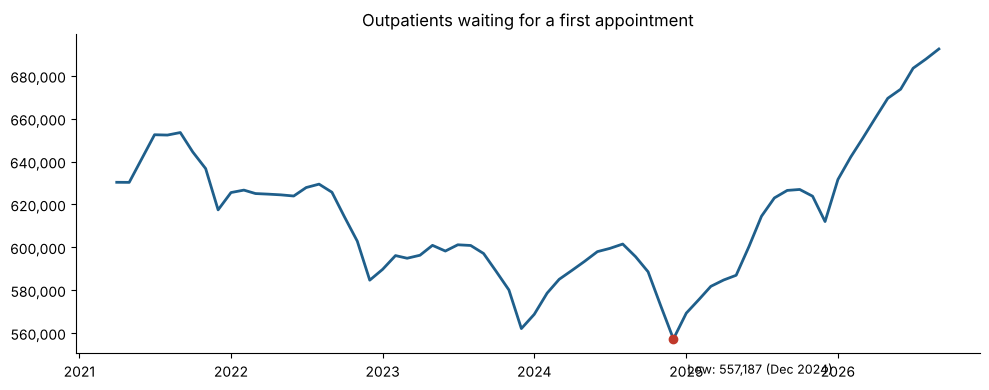

In [9]:
low = monthly.loc[monthly.op_total.idxmin()]
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(monthly.month, monthly.op_total, color="#1f5f8b", lw=2, label="Outpatient")
ax.scatter([low.month], [low.op_total], color="#c0392b", zorder=3)
ax.annotate(f"Low: {low.op_total:,.0f} ({low.month:%b %Y})", (low.month, low.op_total),
            xytext=(10, -25), textcoords="offset points", fontsize=9)
ax.set_title("Outpatients waiting for a first appointment")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
plt.tight_layout(); plt.savefig("../images/01_outpatient_trend.png", dpi=150); plt.show()

since_low = (last.op_total - low.op_total) / low.op_total * 100
print(f"Lowest point: {low.op_total:,.0f} in {low.month:%b %Y}; up {since_low:.1f}% since then.")

### Long waiters

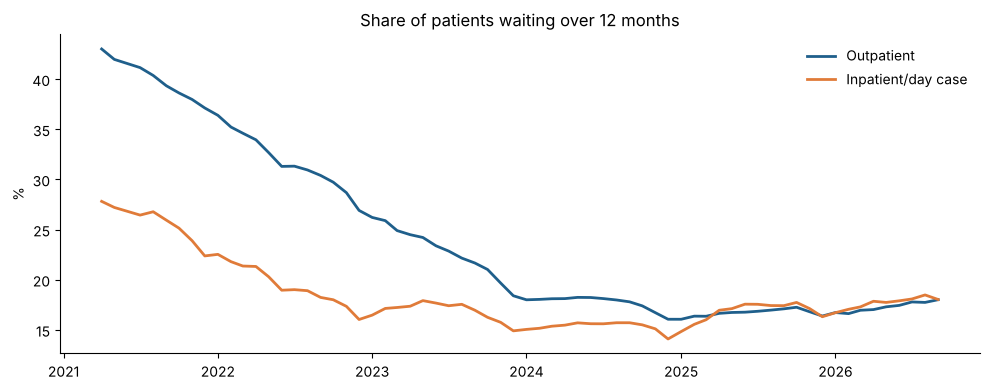

In [11]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(monthly.month, monthly.op_pct_over_12m, color="#1f5f8b", lw=2, label="Outpatient")
ax.plot(monthly.month, monthly.ipdc_pct_over_12m, color="#e07b39", lw=2, label="Inpatient/day case")
ax.set_title("Share of patients waiting over 12 months")
ax.set_ylabel("%"); ax.legend(frameon=False)
plt.tight_layout(); plt.savefig("../images/02_long_wait_share.png", dpi=150); plt.show()

### Specialties and hospitals (September 2026)

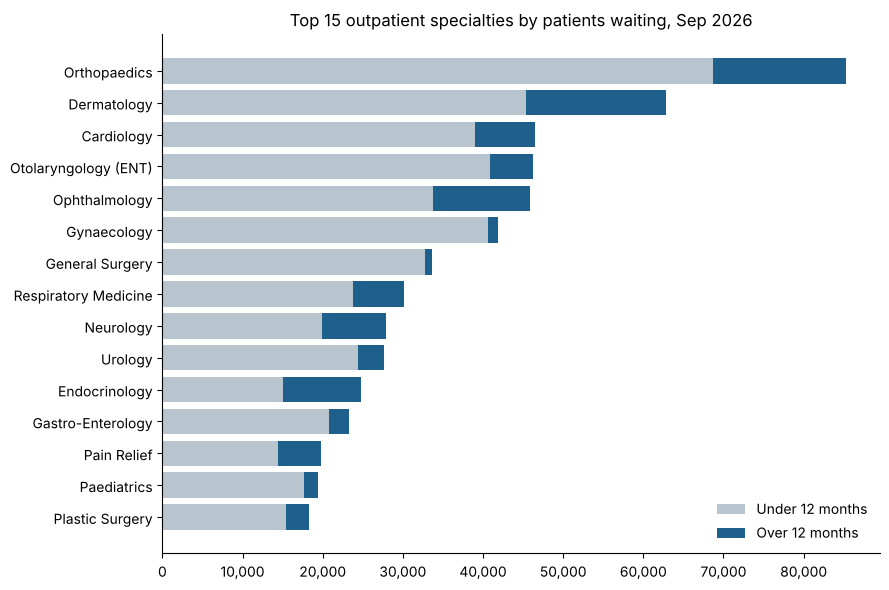

,specialty,total_sep2026,over_12m_sep2026,total_sep2025,pct_over_12m,yoy_change_pct
0,Orthopaedics,85258,16596,72811,19.5,17.1
1,Dermatology,62846,17435,63850,27.7,-1.6
2,Cardiology,46535,7550,41093,16.2,13.2
3,Otolaryngology (ENT),46274,5356,43756,11.6,5.8
4,Ophthalmology,45902,12144,40960,26.5,12.1
5,Gynaecology,41899,1299,35009,3.1,19.7
6,General Surgery,33679,894,33955,2.7,-0.8
7,Respiratory Medicine,30166,6408,26021,21.2,15.9
8,Neurology,27887,8035,22718,28.8,22.8
9,Urology,27595,3172,26339,11.5,4.8


In [13]:
op_spec["pct_over_12m"] = op_spec.over_12m_sep2026 / op_spec.total_sep2026 * 100
op_spec["yoy_change_pct"] = (op_spec.total_sep2026 - op_spec.total_sep2025) / op_spec.total_sep2025 * 100
top = op_spec.sort_values("total_sep2026")
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top.specialty, top.total_sep2026 - top.over_12m_sep2026, color="#b8c4ce", label="Under 12 months")
ax.barh(top.specialty, top.over_12m_sep2026, left=top.total_sep2026 - top.over_12m_sep2026, color="#1f5f8b", label="Over 12 months")
ax.set_title("Top 15 outpatient specialties by patients waiting, Sep 2026")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.legend(frameon=False, loc="lower right")
plt.tight_layout(); plt.savefig("../images/03_top_specialties.png", dpi=150); plt.show()

op_spec.sort_values("total_sep2026", ascending=False).round(1).head(15)

In [14]:
op_hosp["yoy_change_pct"] = (op_hosp.total_sep2026 - op_hosp.total_sep2025) / op_hosp.total_sep2025 * 100
op_hosp["pct_over_12m"] = op_hosp.over_12m_sep2026 / op_hosp.total_sep2026 * 100
op_hosp.round(1)

,hospital,total_sep2026,over_12m_sep2026,total_sep2025,yoy_change_pct,pct_over_12m
0,Beaumont Hospital,56012,11594,47273,18.5,20.7
1,Galway University Hospitals,53045,11112,51576,2.8,20.9
2,University Hospital Waterford,50700,11287,48061,5.5,22.3
3,Mater Misericordiae University Hospital,43910,8244,41669,5.4,18.8
4,University Hospital Limerick,36149,4700,28985,24.7,13.0
5,St. Vincent's University Hospital,34691,7931,34361,1.0,22.9
6,South Infirmary Victoria University Hospital,33023,7771,32817,0.6,23.5
7,Children's Health Ireland,32484,4933,33229,-2.2,15.2
8,Tallaght University Hospital,31780,4813,25220,26.0,15.1
9,St. James's Hospital,29780,4359,25784,15.5,14.6


## 4. Forecasting model

**Why model the monthly change, not the level?** A Random Forest cannot predict values outside the range it was trained on. The waiting list reached a record high in 2026, so a model trained on the level would always under-forecast. Instead the model predicts the month-to-month change, which is added to the last known level.

**Features:** the change 1, 2, 3, 6 and 12 months earlier, a 3-month rolling average and the month of the year.

**Testing:** walk-forward validation on the last 6 months. Each month is predicted using only the months before it, then compared with a simple baseline (repeat last month's figure). A model is only useful if it beats that baseline.

In [16]:
series = monthly.set_index("month")[["op_total", "ipdc_total"]].asfreq("MS").interpolate()

def make_features(s):
    f = pd.DataFrame({"y": s})
    for lag in (1, 2, 3, 6, 12):
        f[f"lag_{lag}"] = f["y"].shift(lag)
    f["rolling_3"] = f["y"].shift(1).rolling(3).mean()
    f["month_of_year"] = f.index.month
    return f

results, forecasts = [], {}
for col, name in [("op_total", "Outpatient"), ("ipdc_total", "Inpatient/Day Case")]:
    s = series[col]
    change = s.diff()
    feat = make_features(change).dropna()
    X, y = feat.drop(columns="y"), feat["y"]

    preds, naive, actual = [], [], []
    for i in range(len(feat) - 6, len(feat)):
        model = RandomForestRegressor(n_estimators=300, random_state=42).fit(X.iloc[:i], y.iloc[:i])
        prev_level = s.iloc[s.index.get_loc(feat.index[i]) - 1]
        preds.append(prev_level + model.predict(X.iloc[[i]])[0])
        naive.append(prev_level)
        actual.append(s.loc[feat.index[i]])
    actual = np.array(actual)
    results.append({"List": name,
                    "Random Forest error %": np.mean(np.abs(actual - preds) / actual) * 100,
                    "Repeat-last-month error %": np.mean(np.abs(actual - naive) / actual) * 100})

    model = RandomForestRegressor(n_estimators=300, random_state=42).fit(X, y)
    hist, level, out = change.copy(), s.iloc[-1], []
    for _ in range(6):
        nm = hist.index[-1] + pd.offsets.MonthBegin(1)
        hist.loc[nm] = np.nan
        step = model.predict(make_features(hist).iloc[[-1]].drop(columns="y"))[0]
        hist.loc[nm] = step
        level += step
        out.append((nm, level))
    forecasts[name] = pd.Series(dict(out))

pd.DataFrame(results).round(2)

,List,Random Forest error %,Repeat-last-month error %
0,Outpatient,0.49,1.03
1,Inpatient/Day Case,0.87,0.49


- **Outpatients:** the Random Forest roughly halves the error of the simple baseline, so it adds real value.
- **Inpatient/day case:** the model does **not** beat the baseline. This list changes very steadily month to month, so simply repeating last month is already very accurate. I report this honestly rather than hiding it.

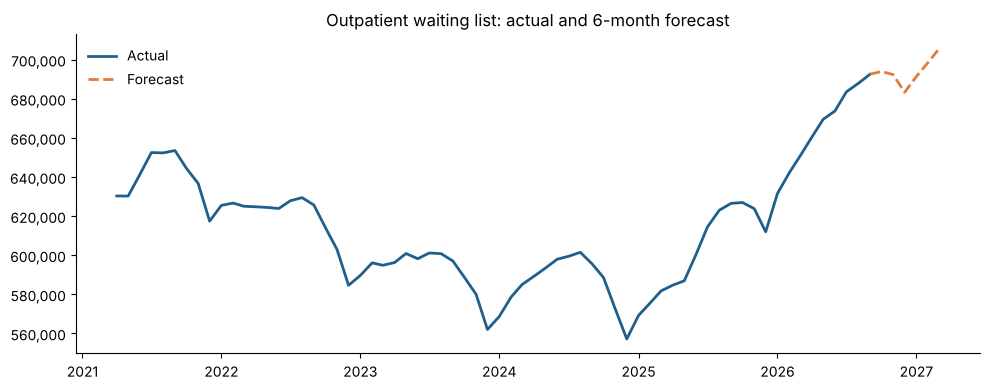

,Forecast patients waiting
2026-10-01,693966
2026-11-01,692340
2026-12-01,683286
2027-01-01,691424
2027-02-01,698634
2027-03-01,705463


In [18]:
fc = forecasts["Outpatient"]
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(series.index, series.op_total, color="#1f5f8b", lw=2, label="Actual")
ax.plot([series.index[-1], *fc.index], [series.op_total.iloc[-1], *fc.values], color="#e07b39", lw=2, ls="--", label="Forecast")
ax.set_title("Outpatient waiting list: actual and 6-month forecast")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.legend(frameon=False)
plt.tight_layout(); plt.savefig("../images/04_outpatient_forecast.png", dpi=150); plt.show()

fc.round(0).astype(int).rename("Forecast patients waiting").to_frame()

## 5. Limitations

- NTPF publishes snapshots of patients **waiting**, not patients treated or referred, so the model forecasts list size, not demand.
- 65 months is a short history for forecasting, and the 6-month forecast is built step by step from predicted values, so uncertainty grows further ahead. Accuracy was tested one month ahead.
- The specialty and hospital views cover the largest entries only.